In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline

In [45]:
df=pd.read_csv("automobiles_clean_df.csv")

In [46]:
df.isnull().sum()

Unnamed: 0           0
symboling            0
normalized-losses    0
make                 0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
highway-L/100km      0
horsepower-binned    0
fuel-type-diesel     0
fuel-type-gas        0
aspiration-std       0
aspiration-turbo     0
dtype: int64

In [47]:
df.dtypes

Unnamed: 0             int64
symboling              int64
normalized-losses      int64
make                  object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                 float64
stroke               float64
compression-ratio    float64
horsepower             int64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64
city-L/100km         float64
highway-L/100km      float64
horsepower-binned     object
fuel-type-diesel        bool
fuel-type-gas           bool
aspiration-std          bool
aspiration-turbo        bool
dtype: object

In [48]:
df.columns

Index(['Unnamed: 0', 'symboling', 'normalized-losses', 'make', 'num-of-doors',
       'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length',
       'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders',
       'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio',
       'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price',
       'city-L/100km', 'highway-L/100km', 'horsepower-binned',
       'fuel-type-diesel', 'fuel-type-gas', 'aspiration-std',
       'aspiration-turbo'],
      dtype='object')

In [49]:
df[["bore","stroke","compression-ratio","horsepower"]].corr()

,bore,stroke,compression-ratio,horsepower
bore,1.000000,-0.051087,0.002021,0.566690
stroke,-0.051087,1.000000,0.186761,0.100351
compression-ratio,0.002021,0.186761,1.000000,-0.214162
horsepower,0.566690,0.100351,-0.214162,1.000000


<Axes: xlabel='engine-size', ylabel='price'>

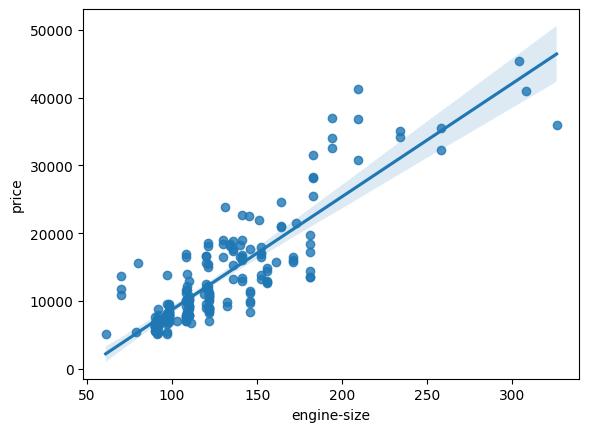

In [50]:
sns.regplot(x="engine-size",y="price", data=df)

In [51]:
df[["engine-size","price"]].corr()

,engine-size,price
engine-size,1.000000,0.872337
price,0.872337,1.000000


<Axes: xlabel='highway-mpg', ylabel='price'>

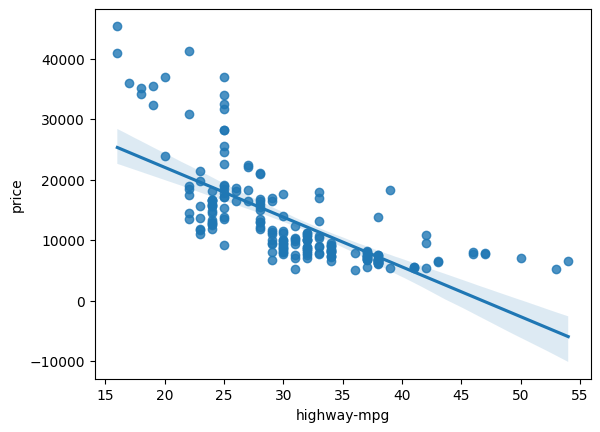

In [52]:
sns.regplot(x='highway-mpg', y='price', data=df)

In [53]:
df[["highway-mpg", "price"]].corr()

,highway-mpg,price
highway-mpg,1.000000,-0.705115
price,-0.705115,1.000000


<Axes: xlabel='peak-rpm', ylabel='price'>

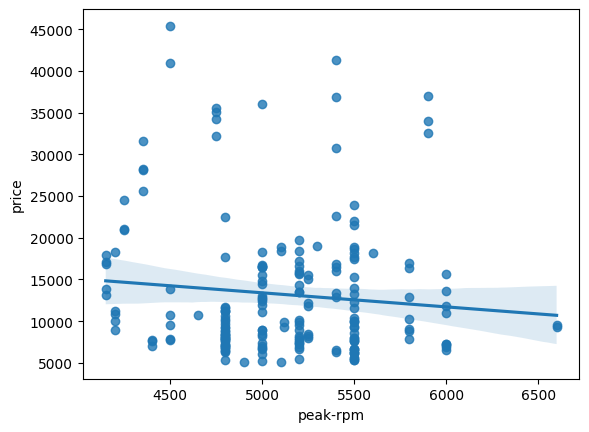

In [54]:
sns.regplot(x="peak-rpm", y="price", data=df)

In [55]:
df[["peak-rpm","price"]].corr()

,peak-rpm,price
peak-rpm,1.000000,-0.101519
price,-0.101519,1.000000


<Axes: xlabel='stroke', ylabel='price'>

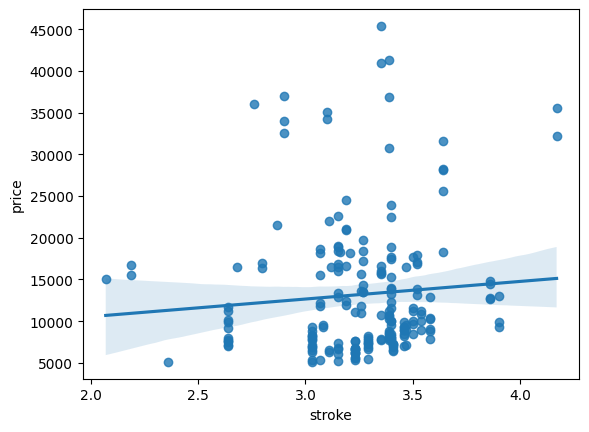

In [56]:
sns.regplot(x="stroke", y="price", data=df)

In [57]:
df[["price","stroke"]].corr()

,price,stroke
price,1.000000,0.083296
stroke,0.083296,1.000000


<Axes: xlabel='body-style', ylabel='price'>

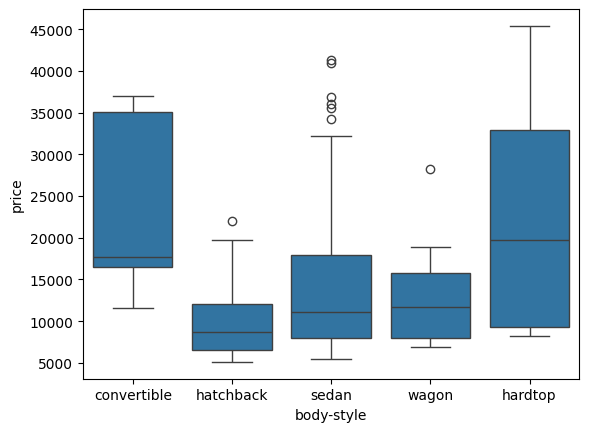

In [58]:
#categorical variables
sns.boxplot(x="body-style", y="price", data=df)

<Axes: xlabel='engine-location', ylabel='price'>

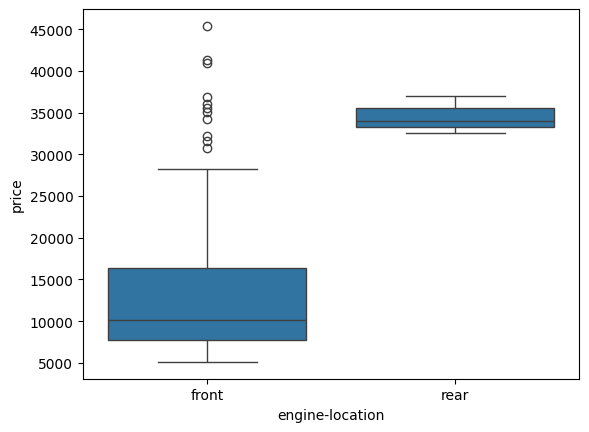

In [59]:
sns.boxplot(x="engine-location",y="price", data=df)

<Axes: xlabel='drive-wheels', ylabel='price'>

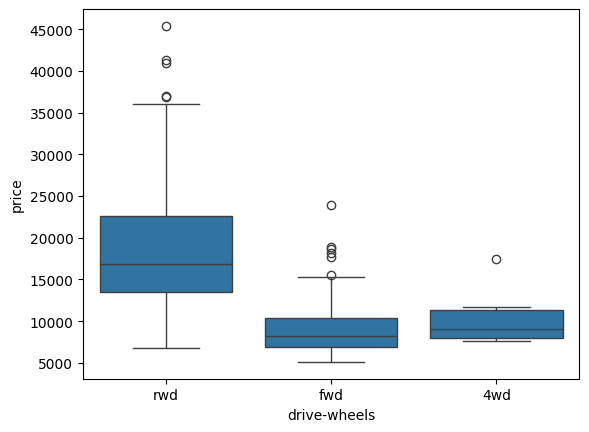

In [60]:
sns.boxplot(x="drive-wheels", y="price", data=df)

In [61]:
df.describe(include=["object"])

,make,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system,horsepower-binned
count,200,200,200,200,200,200,200,200,200
unique,22,2,5,3,2,6,7,8,3
top,toyota,four,sedan,fwd,front,ohc,four,mpfi,Low
freq,32,115,94,118,197,145,156,91,152


In [62]:
df["drive-wheels"].value_counts().to_frame()

,count
drive-wheels,
fwd,118
rwd,74
4wd,8


In [63]:
df["engine-location"].value_counts().to_frame()

,count
engine-location,
front,197
rear,3


In [64]:
#Grouping
df["drive-wheels"].unique()

array(['rwd', 'fwd', '4wd'], dtype=object)

In [65]:
df_group_one = df[["drive-wheels","body-style","price"]]

In [ ]:
df.groupby(["drive-wheels","body-style"])["price"].mean()

drive-wheels  body-style 
4wd           hatchback       7603.000000
              sedan          12647.333333
              wagon           9095.750000
fwd           convertible    11595.000000
              hardtop         8249.000000
              hatchback       8396.387755
              sedan           9811.800000
              wagon           9997.333333
rwd           convertible    26563.250000
              hardtop        24202.714286
              hatchback      14337.777778
              sedan          21711.833333
              wagon          16994.222222
Name: price, dtype: float64

In [67]:
df_group_one = df_group_one.groupby(['drive-wheels','body-style']).mean()
df_group_one


price
drive-wheels body-style               
4wd          hatchback     7603.000000
             sedan        12647.333333
             wagon         9095.750000
fwd          convertible  11595.000000
             hardtop       8249.000000
             hatchback     8396.387755
             sedan         9811.800000
             wagon         9997.333333
rwd          convertible  26563.250000
             hardtop      24202.714286
             hatchback    14337.777778
             sedan        21711.833333
             wagon        16994.222222

In [70]:
grouped_pivot = pd.pivot_table(df_group_one, index='drive-wheels', columns='body-style').fillna(0)
grouped_pivot

price                                            \
body-style   convertible       hardtop     hatchback         sedan   
drive-wheels                                                         
4wd                 0.00      0.000000   7603.000000  12647.333333   
fwd             11595.00   8249.000000   8396.387755   9811.800000   
rwd             26563.25  24202.714286  14337.777778  21711.833333   

                            
body-style           wagon  
drive-wheels                
4wd            9095.750000  
fwd            9997.333333  
rwd           16994.222222

<Axes: xlabel='None-body-style', ylabel='drive-wheels'>

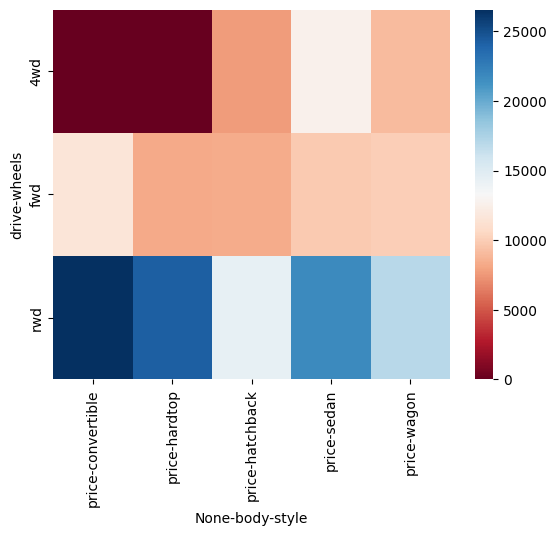

In [71]:
sns.heatmap(grouped_pivot, cmap='RdBu')

In [76]:
pearsone_coef, p_value = stats.pearsonr(df["wheel-base"], df["price"])
print(f"Person coefficient: {pearsone_coef} \nP-Value: {p_value}")
#if the p_value is <0.001 then the correlation is statistically significant

Person coefficient: 0.5891470005448702 
P-Value: 4.457019502050249e-20


In [77]:
pearsone_coef, p_value = stats.pearsonr(df["horsepower"], df["price"])
print(f"Person coefficient: {pearsone_coef} \nP-Value: {p_value}")

Person coefficient: 0.8097789763551084 
P-Value: 9.887379251280393e-48


In [78]:
pearsone_coef, p_value = stats.pearsonr(df["length"], df["price"])
print(f"Person coefficient: {pearsone_coef} \nP-Value: {p_value}")

Person coefficient: 0.6910440897821905 
P-Value: 9.960963222348405e-30


In [79]:
pearsone_coef, p_value = stats.pearsonr(df["width"], df["price"])
print(f"Person coefficient: {pearsone_coef} \nP-Value: {p_value}")

Person coefficient: 0.7527948631832612 
P-Value: 8.256714148308014e-38


In [81]:
pearsone_coef, p_value = stats.pearsonr(df["curb-weight"], df["price"])
print(f"Person coefficient: {pearsone_coef} \nP-Value: {p_value}")

Person coefficient: 0.8344204348498462 
P-Value: 3.969977536021844e-53


In [82]:
pearsone_coef, p_value = stats.pearsonr(df["engine-size"], df["price"])
print(f"Person coefficient: {pearsone_coef} \nP-Value: {p_value}")

Person coefficient: 0.8723367498521142 
P-Value: 1.897717146656209e-63


In [83]:
pearsone_coef, p_value = stats.pearsonr(df["bore"], df["price"])
print(f"Person coefficient: {pearsone_coef} \nP-Value: {p_value}")

Person coefficient: 0.5434310033088077 
P-Value: 9.209749630850503e-17


In [84]:
pearsone_coef, p_value = stats.pearsonr(df["city-mpg"], df["price"])
print(f"Person coefficient: {pearsone_coef} \nP-Value: {p_value}")

Person coefficient: -0.6871861020862687 
P-Value: 2.7292565684789384e-29


In [85]:
pearsone_coef, p_value = stats.pearsonr(df["highway-mpg"], df["price"])
print(f"Person coefficient: {pearsone_coef} \nP-Value: {p_value}")

Person coefficient: -0.7051147088046403 
P-Value: 2.197326053158349e-31


In [86]:
#Anova - categorical variables vs Target Variable
#Pearson co-efficeint - Continous variables vs Target Variables

In [128]:
grouped_test2 = df[["drive-wheels","price"]].groupby(["drive-wheels"])
grouped_test2.head(2)

,drive-wheels,price
0,rwd,16500.0
1,rwd,16500.0
2,fwd,13950.0
3,4wd,17450.0
4,fwd,15250.0
135,4wd,7603.0


In [132]:
grouped_test2.get_group('4wd')["price"]

/tmp/ipykernel_1502/1513962262.py:1: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  grouped_test2.get_group('4wd')["price"]


3      17450.0
135     7603.0
139     9233.0
140    11259.0
143     8013.0
144    11694.0
149     7898.0
150     8778.0
Name: price, dtype: float64

In [133]:
f_val, p_val = stats.f_oneway(grouped_test2.get_group('fwd')['price'], grouped_test2.get_group('rwd')['price'], grouped_test2.get_group('4wd')['price'])
print(f"Anova results F score = {f_val}\nP-score = {p_val}")

Anova results F score = 68.49603532807176
P-score = 2.6116313994533863e-23


/tmp/ipykernel_1502/771687165.py:1: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  f_val, p_val = stats.f_oneway(grouped_test2.get_group('fwd')['price'], grouped_test2.get_group('rwd')['price'], grouped_test2.get_group('4wd')['price'])


In [134]:
f_val, p_val = stats.f_oneway(grouped_test2.get_group('fwd')['price'], grouped_test2.get_group('rwd')['price'])
print(f"Anova results F score = {f_val}\nP-score = {p_val}")

Anova results F score = 131.59324661179534
P-score = 1.7388247444783448e-23


/tmp/ipykernel_1502/2540488067.py:1: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  f_val, p_val = stats.f_oneway(grouped_test2.get_group('fwd')['price'], grouped_test2.get_group('rwd')['price'])


In [135]:
f_val, p_val = stats.f_oneway( grouped_test2.get_group('rwd')['price'], grouped_test2.get_group('4wd')['price'])
print(f"Anova results F score = {f_val}\nP-score = {p_val}")

Anova results F score = 8.67069478113451
P-score = 0.004232262975461328


/tmp/ipykernel_1502/2658129073.py:1: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  f_val, p_val = stats.f_oneway( grouped_test2.get_group('rwd')['price'], grouped_test2.get_group('4wd')['price'])


In [136]:
f_val, p_val = stats.f_oneway(grouped_test2.get_group('fwd')['price'], grouped_test2.get_group('4wd')['price'])
print(f"Anova results F score = {f_val}\nP-score = {p_val}")

Anova results F score = 0.6654657502523033
P-score = 0.41620116697845666


/tmp/ipykernel_1502/531534924.py:1: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  f_val, p_val = stats.f_oneway(grouped_test2.get_group('fwd')['price'], grouped_test2.get_group('4wd')['price'])


In [137]:
df.describe(include=["object"])

,make,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system,horsepower-binned
count,200,200,200,200,200,200,200,200,200
unique,22,2,5,3,2,6,7,8,3
top,toyota,four,sedan,fwd,front,ohc,four,mpfi,Low
freq,32,115,94,118,197,145,156,91,152


In [139]:
englof_group = df[["engine-location","price"]].groupby(["engine-location"])
englof_group.head(1)

,engine-location,price
0,front,16500.0
122,rear,32528.0


In [141]:
f_val, p_val = stats.f_oneway(englof_group.get_group('front')['price'], englof_group.get_group('rear')['price'])
print(f"Anova results F score = {f_val}\nP-score = {p_val}")

Anova results F score = 24.37840781261946
P-score = 1.677437100934909e-06


/tmp/ipykernel_1502/2497602737.py:1: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  f_val, p_val = stats.f_oneway(englof_group.get_group('front')['price'], englof_group.get_group('rear')['price'])
